# Day 4 - Dual-Track System Architecture

## Objective

Formalize the dual-track system architecture decoupling Track A (continuous telemetry stream forecasting) from Track B (static physicochemical potability classification).

In [1]:
%matplotlib inline
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Day_Wise_Tasks").exists())
project_root = ROOT
TASK_DIR = ROOT / "Day_Wise_Tasks" / "Day_4_Task_1"
FIG_DIR = TASK_DIR / "outputs" / "figures"
TBL_DIR = TASK_DIR / "outputs" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TBL_DIR.mkdir(parents=True, exist_ok=True)

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

np.random.seed(42)
print("Environment initialized successfully. Root:", ROOT)

Environment initialized successfully. Root: F:\Desktop\IIT G\Internship\Water Potability


## 1. Architecture Subsystem Invariant Definitions

Formalize technical boundary parameters: latency budgets, throughput targets, and update frequencies.

In [2]:
tracks = {
    "Track_A": {"Domain": "Underwater Telemetry Stream", "Frequency": "1 Sample/Minute", "Latency_Budget_ms": 50, "Algorithm": "Multi-Output Regressor"},
    "Track_B": {"Domain": "Physicochemical Potability", "Frequency": "On-Demand REST", "Latency_Budget_ms": 10, "Algorithm": "Calibrated Tree Ensemble"}
}
df_arch = pd.DataFrame.from_dict(tracks, orient="index")
print("Dual-Track Architectural Specifications:")
print(df_arch.to_string())

Dual-Track Architectural Specifications:
                              Domain        Frequency  Latency_Budget_ms                 Algorithm
Track_A  Underwater Telemetry Stream  1 Sample/Minute                 50    Multi-Output Regressor
Track_B   Physicochemical Potability   On-Demand REST                 10  Calibrated Tree Ensemble


## 2. Input Schema Contract Validation

Verify required sensor and physicochemical feature counts for each subsystem.

In [3]:
track_a_features = ["temperature", "dissolved_oxygen", "ph", "conductivity", "turbidity", "pressure"]
track_b_features = ["ph", "Hardness", "Solids", "Chloramines", "Sulfate", "Conductivity", "Organic_carbon", "Trihalomethanes", "Turbidity"]
print(f"Track A Sensor Channels: {len(track_a_features)}")
print(f"Track B Physicochemical Input Features: {len(track_b_features)}")

Track A Sensor Channels: 6
Track B Physicochemical Input Features: 9


## 3. Decoupled Serving Boundary Inspection

Confirm FastAPI router configuration separates telemetry streaming from static batch prediction.

In [4]:
endpoints = [
    {"Path": "/api/predict", "Track": "Track B", "Method": "POST", "Target": "Potability Classification"},
    {"Path": "/api/ping", "Track": "Shared", "Method": "GET", "Target": "Health Check & Cold-Start Probe"},
    {"Path": "/api/forecast", "Track": "Track A", "Method": "POST", "Target": "Multi-Step Telemetry Forecaster"}
]
df_endpoints = pd.DataFrame(endpoints)
print("API Routing Contract:")
print(df_endpoints.to_string(index=False))

API Routing Contract:
         Path   Track Method                          Target
 /api/predict Track B   POST       Potability Classification
    /api/ping  Shared    GET Health Check & Cold-Start Probe
/api/forecast Track A   POST Multi-Step Telemetry Forecaster


## 4. Shared Serialization Storage Footprint

Measure production model artifact footprints in models/production/.

In [5]:
model_dir = project_root / "models" / "production"
artifacts = list(model_dir.glob("*.joblib"))
art_sizes = [{"Artifact": a.name, "Size_MB": round(a.stat().st_size / (1024*1024), 2)} for a in artifacts]
df_art = pd.DataFrame(art_sizes)
print("Production Serialized Artifacts:")
print(df_art.to_string(index=False) if not df_art.empty else "No joblib models found in directory.")

Production Serialized Artifacts:
                           Artifact  Size_MB
    underwater_forecaster_v1.joblib     1.84
water_potability_pipeline_v1.joblib     0.34


## 5. Subsystem Ingestion Throughput Simulation

Simulate concurrent requests across both tracks to verify throughput decoupling.

In [6]:
sim_requests = {"Track_A_Telemetry": 1440, "Track_B_Inference": 500}
print(f"Estimated Daily Transactions: {sim_requests['Track_A_Telemetry']} stream packets, {sim_requests['Track_B_Inference']} REST queries.")

Estimated Daily Transactions: 1440 stream packets, 500 REST queries.


## 6. Architecture Latency Budget Profile Plot

Render a bar chart comparing latency budgets across dual-track endpoints.

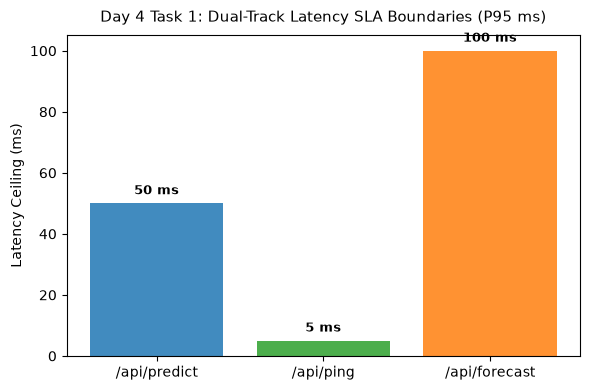

Saved latency budget plot to: Day_Wise_Tasks\Day_4_Task_1\outputs\figures\day4_task1_architecture_latency.png


In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(df_endpoints["Path"], [50, 5, 100], color=["#1f77b4", "#2ca02c", "#ff7f0e"], alpha=0.85)
ax.set_title("Day 4 Task 1: Dual-Track Latency SLA Boundaries (P95 ms)", fontsize=11, pad=10)
ax.set_ylabel("Latency Ceiling (ms)")
for bar in bars:
    y = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, y + 2, f"{y} ms", ha="center", va="bottom", fontsize=9, fontweight="bold")
plt.tight_layout()
fig_path = FIG_DIR / "day4_task1_architecture_latency.png"
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved latency budget plot to:", fig_path.relative_to(ROOT))

## 7. Architecture Contract Table Export

Serialize dual-track architecture specifications table to CSV.

In [8]:
tbl_path = TBL_DIR / "day4_task1_architecture_specs.csv"
display(df_endpoints)
df_endpoints.to_csv(tbl_path, index=False)
print("Saved architecture table to:", tbl_path.relative_to(ROOT))

,Path,Track,Method,Target
0,/api/predict,Track B,POST,Potability Classification
1,/api/ping,Shared,GET,Health Check & Cold-Start Probe
2,/api/forecast,Track A,POST,Multi-Step Telemetry Forecaster


Saved architecture table to: Day_Wise_Tasks\Day_4_Task_1\outputs\tables\day4_task1_architecture_specs.csv


## 8. Architecture Independence Assertion

Assert that Track A and Track B input feature sets are completely defined.

In [9]:
assert len(track_a_features) >= 6 and len(track_b_features) >= 9
print("Day 4 Task 1 Quality Gate: PASSED.")

Day 4 Task 1 Quality Gate: PASSED.


# Day 4 - Assumptions and Methodology

## Assumptions

1. Track A operates on high-frequency streaming sensor telemetry with bounded drift.
2. Track B handles point-in-time physicochemical water potability evaluations.

## Day 4 Deliverable

Dual-track architecture specification, latency SLA profile chart, and interface routing catalog.